# P9: CNN y BiLSTM para palabras clave

**Contenido del notebook.**
1. Construir entradas log-mel que conserven la secuencia temporal.
2. Entrenar y evaluar una CNN-BiLSTM para clasificar palabras aisladas.

Usamos cuatro palabras de `mini_speech_commands`: `yes`, `no`, `up` y `down`. Cada audio contiene una de esas palabras (no hay posibilidad de encontrar silencios o palabras desconocidas).

In [1]:
import zipfile
import json
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from copy import deepcopy
from pathlib import Path
from scipy.io import wavfile
from IPython.display import Audio, display
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay

np.random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(2)
np.set_printoptions(precision=3, suppress=True)

## Ejercicio 3. Preparación de secuencias para LSTM

- Realizar la carga y el *splitting*. Los hablantes se separan antes de seleccionar los audios tal que ninguno aparezca en más de una partición/*split*. Usamos 200 audios por clase para train y 50 por clase para validación y test. Es decir, 800, 200 y 200 audios, respectivamente.
- Ejecutar `cargar_wav_1s`: la idea es normalizar el pico y completar con ceros al final hasta un segundo. Si el audio es más largo, conservamos el primer segundo.
- Usar algunas funciones de la P3 (MFCC) sin cambios. Completar el logaritmo en `extraer_logmel`.
- Normalizar y preparar los tensores.

In [2]:
data_dir = Path('data/P9_datos')
zip_path = Path('P9_datos.zip')
if not (data_dir / 'particion.json').exists():
    if not zip_path.exists():
        raise FileNotFoundError('Colocar P9_datos.zip en la misma carpeta que el notebook antes de ejecutar.')
    data_dir.parent.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path) as archivo:
        archivo.extractall(data_dir.parent)

comandos = ['yes', 'no', 'up', 'down']
clase = {palabra: i for i, palabra in enumerate(comandos)}
wav_paths = sorted(p for palabra in comandos for p in (data_dir / palabra).glob('*.wav'))
print('Audios:', len(wav_paths))

Audios: 1200


In [3]:
with open(data_dir / 'particion.json', encoding='utf-8') as archivo:
    particion = json.load(archivo)
particion = {('val' if nombre.startswith('val') else nombre): archivos for nombre, archivos in particion.items()}

paths_train = [data_dir / nombre for nombre in particion['train']]
paths_val = [data_dir / nombre for nombre in particion['val']]
paths_test = [data_dir / nombre for nombre in particion['test']]
etiquetas_train = np.array([clase[p.parent.name] for p in paths_train])
etiquetas_val = np.array([clase[p.parent.name] for p in paths_val])
etiquetas_test = np.array([clase[p.parent.name] for p in paths_test])

grupos = [{p.stem.split('_nohash_')[0] for p in paths} for paths in [paths_train, paths_val, paths_test]]
assert not (grupos[0] & grupos[1] or grupos[0] & grupos[2] or grupos[1] & grupos[2])
print(f'Train: {len(paths_train)}\nValidación: {len(paths_val)}\nTest: {len(paths_test)}')
print('Hablantes distintos en cada partición:', [len(g) for g in grupos])

Train: 800
Validación: 200
Test: 200
Hablantes distintos en cada partición: [489, 134, 135]


In [4]:
fs = 16000
muestras_por_audio = fs # concuerdan al tener audios de 1s

def cargar_wav_1s(path, sample_rate=fs, target_len=muestras_por_audio):
    fs, x = wavfile.read(path)
    if fs != sample_rate:
        raise ValueError(f"Sample rate inesperado en {path}: {fs}")

    x = torch.tensor(x, dtype=torch.float32)

    if x.ndim > 1:
        x = x.mean(dim=1)

    if x.abs().max() > 0:
        x = x / x.abs().max()

    if x.numel() < target_len:
        x = torch.nn.functional.pad(x, (0, target_len - x.numel()))
    else:
        x = x[:target_len]

    return x

Usamos $f_s=16000$ Hz, $L=400$ muestras (25 ms), $N_{\mathrm{FFT}}=400$, hop de 160 muestras (10 ms), $M=40$ filtros de mel entre 0 y 8000 Hz y $\varepsilon=10^{-6}$. Calculamos

$$
\overset{\sim}{E}_m[t]=\log(E_m[t]+\varepsilon),
\qquad \mathbf y_t=[\overset{\sim}{E}_1[t],\ldots,\overset{\sim}{E}_{40}[t]]^T.
$$

Cada señal de 16000 muestras produce $T=1+\lfloor(16000-400)/160\rfloor=98$ frames. No vamos a aplicar preénfasis ni DCT.

In [7]:
def hz_to_mel(f):
    return 2595 * np.log10(1 + f / 700)

def mel_to_hz(m):
    return 700 * (10**(m / 2595) - 1)

def enmarcar(senial, fs, win_ms=25, hop_ms=10):
    win_len = int(round(win_ms * 1e-3 * fs))
    hop_len = int(round(hop_ms * 1e-3 * fs))
    n_frames = 1 + (len(senial) - win_len) // hop_len
    frames = np.stack([senial[i*hop_len:i*hop_len+win_len] for i in range(n_frames)])
    ventana = np.hamming(win_len)
    return frames * ventana, win_len, hop_len

def banco_mel(n_mels, n_fft, fs, f_min=0, f_max=None):
    if f_max is None:
        f_max = fs / 2

    # M filtros necesitan M+2 puntos de quiebre.
    puntos_mel = np.linspace(hz_to_mel(f_min), hz_to_mel(f_max), n_mels + 2)
    puntos_hz = mel_to_hz(puntos_mel)
    bins = np.floor(n_fft * puntos_hz / fs).astype(int)
    bins = np.clip(bins, 0, n_fft // 2)

    banco = np.zeros((n_mels, n_fft//2 + 1))
    for m in range(1, n_mels + 1):
        izq, centro, der = bins[m-1], bins[m], bins[m+1]
        for k in range(izq, centro):
            banco[m-1, k] = (k - izq) / max(centro - izq, 1)
        for k in range(centro, der):
            banco[m-1, k] = (der - k) / max(der - centro, 1)
    return banco, puntos_hz

In [9]:
win_ms = 25
hop_ms = 10
n_fft = 400
n_mels = 40
eps = 1e-6

def extraer_logmel(path):
    audio = cargar_wav_1s(path).numpy()
    frames, _, _ = enmarcar(audio, fs, win_ms=win_ms, hop_ms=hop_ms)
    x_fft = np.fft.rfft(frames, n=n_fft, axis=1)
    potencia = np.abs(x_fft)**2
    banco, _ = banco_mel(n_mels, n_fft, fs, f_min=0, f_max=fs/2)
    logmel = np.log(potencia @ banco.T + eps) ### <-- COMPLETAR
    return logmel.astype(float)

y_train = [extraer_logmel(p) for p in paths_train]
y_val = [extraer_logmel(p) for p in paths_val]
y_test = [extraer_logmel(p) for p in paths_test]
print('Una secuencia log-mel:', y_train[0].shape)

Una secuencia log-mel: (98, 40)


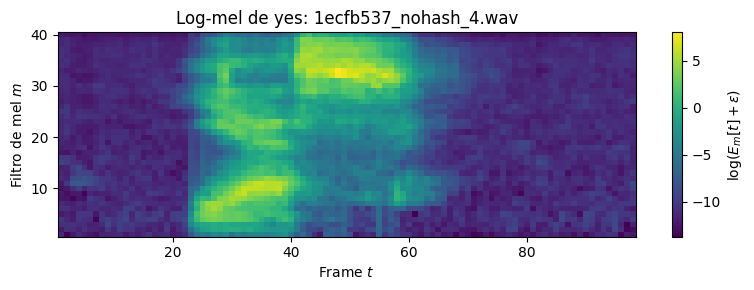

In [10]:
idx = 0
display(Audio(filename=str(paths_train[idx])))
fig, ax = plt.subplots(figsize=(8, 3))
im = ax.imshow(y_train[idx].T, origin='lower', aspect='auto', cmap='viridis', extent=[0.5, 98.5, 0.5, 40.5])
ax.set_xlabel('Frame $t$')
ax.set_ylabel('Filtro de mel $m$')
ax.set_title(f'Log-mel de {paths_train[idx].parent.name}: {paths_train[idx].name}')
fig.colorbar(im, ax=ax, label=r'$\log(E_m[t]+\varepsilon)$')
plt.tight_layout()
plt.show()

Al igual que en P6 y P8, hacemos el fit de `StandardScaler` solamente para el dataset de entrenamiento. Acá cada filtro deriva en un feature. Las funciones de entrenamiento y evaluación conservan la lógica de P8. Esta vez reciben un tensor de cuatro ejes en lugar de un vector de 26 features por audio.

In [11]:
# Hacemos el fit en train y lo aplicamos a train/val/test
scaler = StandardScaler()
scaler.fit(np.vstack(y_train))
u_train = np.stack([scaler.transform(y).T for y in y_train])[:, None, :, :]
u_val = np.stack([scaler.transform(y).T for y in y_val])[:, None, :, :]
u_test = np.stack([scaler.transform(y).T for y in y_test])[:, None, :, :]

u_train = torch.tensor(u_train, dtype=torch.float32)
u_val = torch.tensor(u_val, dtype=torch.float32)
u_test = torch.tensor(u_test, dtype=torch.float32)
labels_train = torch.tensor(etiquetas_train, dtype=torch.long)
labels_val = torch.tensor(etiquetas_val, dtype=torch.long)

dataset_train = TensorDataset(u_train, labels_train)
loader = DataLoader(dataset_train, batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(42))
print('Entradas de la CNN:', u_train.shape)

Entradas de la CNN: torch.Size([800, 1, 40, 98])


**Interpretar.** ¿Qué representan los cuatro ejes de `u_train`?

## Ejercicio 4. CNN-BiLSTM: entrenamiento e inferencia

Podemos resumir a la arquitectura como:

| Etapa | Configuración | Salida |
|---|---|---|
| Entrada | Un canal, 40 filtros de mel, 98 frames | `(B, 1, 40, 98)` |
| Conv2D + ReLU | 8 filtros, kernel 3 x 3, stride 1, padding 1, con *bias* | `(B, 8, 40, 98)` |
| MaxPool2D | Kernel y stride `(2, 1)` | `(B, 8, 20, 98)` |
| Reordenamiento | Colocamos el tiempo antes | `(B, 98, 160)` |
| BiLSTM | Una capa, 32 unidades por dirección, `batch_first=True`, *bias* predeterminados | `(B, 98, 64)` |
| Promedio temporal | Promediar las salidas del BiLSTM sobre el eje de frames | `(B, 64)` |
| Capa lineal | 64 entradas, 4 logits, con *bias* | `(B, 4)` |

- Completar las capas de la `CNNBiLSTM`. En `permute`, indicar el nuevo orden de los ejes. En `reshape`, agrupar canales y filtros de mel sin mezclar posiciones temporales. El segundo valor devuelto por `nn.LSTM` contiene los estados finales y acá lo descartamos. `h` contiene la salida de cada posición.
- Realizar el conteo de parámetros entrenables y compararlo con el ejercicio escrito. Ejecutar el entrenamiento  empleando 42 como semilla, batches de 32, 20 epochs, entropía cruzada y Adam con tasa de aprendizaje $\eta_{\text{NN}}=10^{-3}$. Conservamos el epoch de menor pérdida de validación. 
- Completar `y_pred` tomando el `argmax` de los logits de test. Correr la evaluación, la matriz de confusión y el ejemplo de audio con sus probabilidades asociadas.
- Finalmente, hacemos un experimento en el que invertimos el orden de los frames.

In [28]:
class CNNBiLSTM(nn.Module):
    def __init__(self, n_clases):
        super().__init__()
        self.conv = nn.Conv2d(1, 8, kernel_size=3, stride=1, padding=1) ### <-- COMPLETAR
        self.pool = nn.MaxPool2d(kernel_size=(2, 1), stride=(2, 1)) ### <-- COMPLETAR
        self.lstm = nn.LSTM(input_size=160, hidden_size=32, batch_first=True, bidirectional=True) ### <-- COMPLETAR
        self.fc = nn.Linear(64, n_clases) ### <-- COMPLETAR

    def forward(self, u):
        z = torch.relu(self.conv(u))  ### <-- COMPLETAR
        z = self.pool(z)
        batch_size, n_canales, n_filtros_mel, n_frames = z.shape
        z = z.permute(0, 3, 1, 2)
        z = z.reshape(batch_size, n_frames, n_canales * n_filtros_mel) ### <-- COMPLETAR
        h, _ = self.lstm(z) ### <-- COMPLETAR
        resumen = h.mean(dim=1) ### <-- COMPLETAR
        return self.fc(resumen) ### <-- COMPLETAR

torch.manual_seed(42)
modelo = CNNBiLSTM(n_clases=len(comandos))
print(modelo)
for nombre in ['conv', 'lstm', 'fc']:
    print(nombre, sum(p.numel() for p in getattr(modelo, nombre).parameters()))
print('Parámetros entrenables:', sum(p.numel() for p in modelo.parameters()))

CNNBiLSTM(
  (conv): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=(2, 1), stride=(2, 1), padding=0, dilation=1, ceil_mode=False)
  (lstm): LSTM(160, 32, batch_first=True, bidirectional=True)
  (fc): Linear(in_features=64, out_features=4, bias=True)
)
conv 80
lstm 49664
fc 260
Parámetros entrenables: 50004


In [30]:
criterio = nn.CrossEntropyLoss()
optimizador = torch.optim.Adam(modelo.parameters(), lr=1e-3)

def entrenar_epoch():
    modelo.train()
    total_loss, correctos = 0.0, 0
    for u_batch, labels_batch in loader:
        logits = modelo(u_batch)
        loss = criterio(logits, labels_batch)
        optimizador.zero_grad()
        loss.backward()
        optimizador.step()
        total_loss += loss.item() * len(labels_batch)
        correctos += (logits.argmax(dim=1) == labels_batch).sum().item()
    return total_loss / len(dataset_train), correctos / len(dataset_train)

def evaluar(u, labels):
    modelo.eval()
    with torch.no_grad():
        logits = modelo(u)
        loss = criterio(logits, labels).item()
        acc = (logits.argmax(dim=1) == labels).float().mean().item()
    return loss, acc

In [31]:
historial = []
mejor_loss = np.inf
for epoch in range(1, 21):
    loss_train, acc_train = entrenar_epoch()
    loss_val, acc_val = evaluar(u_val, labels_val)
    historial.append([loss_train, loss_val, acc_train, acc_val])
    if loss_val < mejor_loss:
        mejor_loss = loss_val
        mejor_epoch = epoch
        mejor_estado = deepcopy(modelo.state_dict())
    if epoch == 1 or epoch % 5 == 0:
        print(f'Epoch {epoch}: loss train={loss_train:.3f}, loss val={loss_val:.3f}, acc train={acc_train:.3f}, acc val={acc_val:.3f}')

modelo.load_state_dict(mejor_estado)
print('epoch restaurado:', mejor_epoch)

Epoch 1: loss train=1.318, loss val=1.232, acc train=0.427, acc val=0.610
Epoch 5: loss train=0.763, loss val=0.687, acc train=0.748, acc val=0.785
Epoch 10: loss train=0.506, loss val=0.422, acc train=0.849, acc val=0.880
Epoch 15: loss train=0.328, loss val=0.324, acc train=0.896, acc val=0.890
Epoch 20: loss train=0.217, loss val=0.287, acc train=0.935, acc val=0.910
epoch restaurado: 18


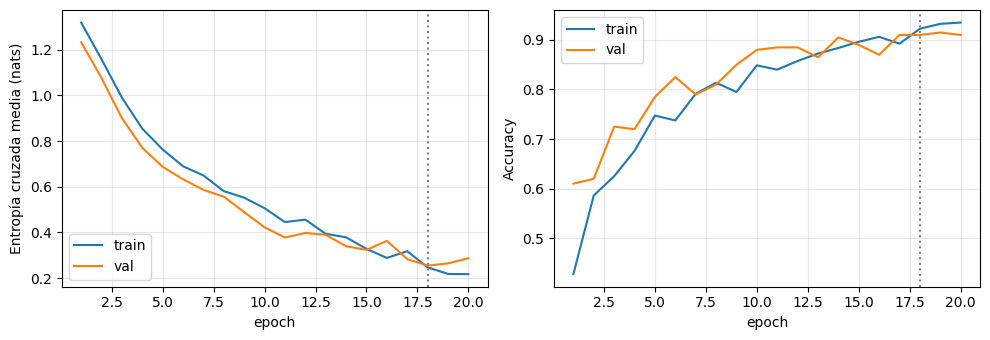

In [32]:
historial = np.array(historial)
epochs = np.arange(1, 21)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(epochs, historial[:, 0], label='train')
axes[0].plot(epochs, historial[:, 1], label='val')
axes[0].set_ylabel('Entropía cruzada media (nats)')
axes[1].plot(epochs, historial[:, 2], label='train')
axes[1].plot(epochs, historial[:, 3], label='val')
axes[1].set_ylabel('Accuracy')
for ax in axes:
    ax.set_xlabel('epoch')
    ax.axvline(mejor_epoch, color='gray', linestyle=':')
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Accuracy de test: 0.910


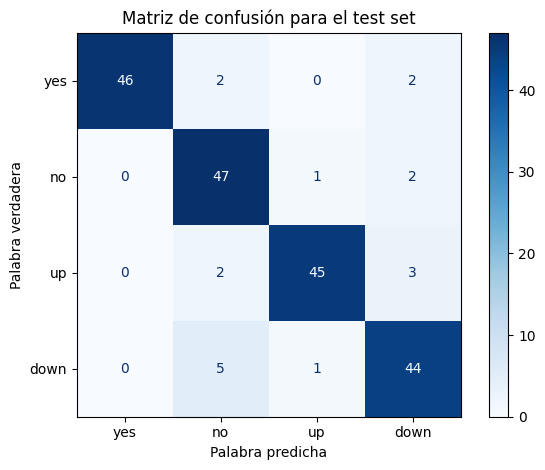

In [34]:
modelo.eval()
with torch.no_grad():
    logits_test = modelo(u_test)
    y_pred = logits_test.argmax(dim=1).numpy() ### <-- COMPLETAR

acc = accuracy_score(etiquetas_test, y_pred)
print(f'Accuracy de test: {acc:.3f}')
cm = confusion_matrix(etiquetas_test, y_pred, labels=list(range(4)))
disp = ConfusionMatrixDisplay(cm, display_labels=comandos)
disp.plot(cmap='Blues', values_format='d')
disp.ax_.set_xlabel('Palabra predicha')
disp.ax_.set_ylabel('Palabra verdadera')
plt.title('Matriz de confusión para el test set')
plt.tight_layout()
plt.show()

Archivo: b575b5fb_nohash_0.wav
Palabra verdadera: yes
Palabra predicha: down


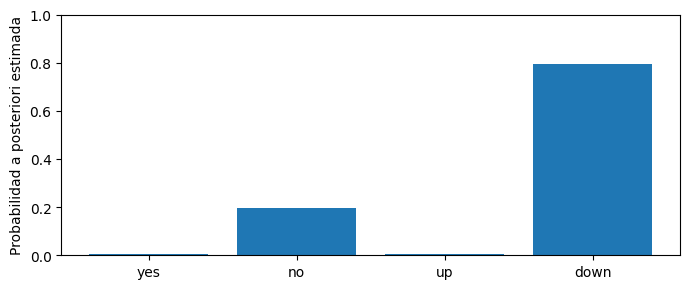

In [35]:
errores = np.flatnonzero(y_pred != etiquetas_test)
idx = int(errores[0]) if len(errores) else 0
with torch.no_grad():
    probabilidades = torch.softmax(modelo(u_test[idx:idx + 1]), dim=1)[0].numpy()
print('Archivo:', paths_test[idx].name)
print('Palabra verdadera:', comandos[etiquetas_test[idx]])
print('Palabra predicha:', comandos[y_pred[idx]])
display(Audio(cargar_wav_1s(paths_test[idx]).numpy(), rate=fs))

plt.figure(figsize=(7, 3))
plt.bar(comandos, probabilidades)
plt.ylabel('Probabilidad a posteriori estimada')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

### ¿Qué ocurre si invertimos el orden de los frames?

Comparamos el mismo ejemplo con su matriz log-mel invertida en el tiempo. Solamente cambia el orden de las columnas y no invertimos la forma de onda ni volvemos a extraer features. La operación se aplica antes de la CNN. Observamos las probabilidades.

Promedio log-mel conservado: True
Máxima diferencia entre probabilidades: 0.11525606


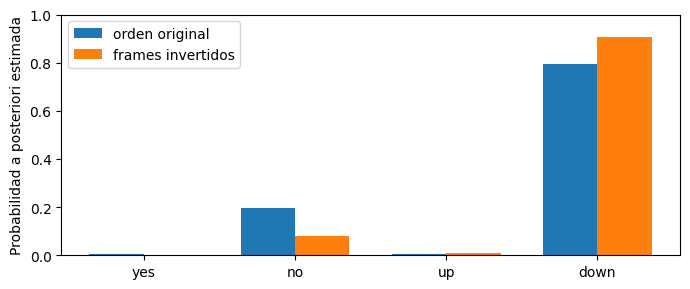

In [36]:
u_original = u_test[idx:idx + 1]
u_invertido = torch.flip(u_original, dims=[3])
with torch.no_grad():
    p_original = torch.softmax(modelo(u_original), dim=1)[0].numpy()
    p_invertido = torch.softmax(modelo(u_invertido), dim=1)[0].numpy()

print('Promedio log-mel conservado:', torch.allclose(u_original.mean(dim=3), u_invertido.mean(dim=3), atol=1e-5))
print('Máxima diferencia entre probabilidades:', np.max(np.abs(p_original - p_invertido)))
fig, ax = plt.subplots(figsize=(7, 3))
posiciones = np.arange(len(comandos))
ax.bar(posiciones - 0.18, p_original, width=0.36, label='orden original')
ax.bar(posiciones + 0.18, p_invertido, width=0.36, label='frames invertidos')
ax.set_xticks(posiciones, comandos)
ax.set_ylabel('Probabilidad a posteriori estimada')
ax.set_ylim(0, 1)
ax.legend()
plt.tight_layout()
plt.show()

**Interpretar.**
¿Qué aporta el BiLSTM después de la CNN? Comparar el contexto temporal que puede utilizar cada uno en esta arquitectura. Si el pooling fuera de tamaño y stride `(2, 2)` en lugar de `(2, 1)`, ¿qué ventaja computacional tendría y qué información relevante para distinguir palabras podría perderse?
* Si bien la CNN ya da información contextual, el BiLSTM aporta aún más información contextual.
* Si el padding es 2x2. Reduce las posiciones temporales
  * Beneficia en menos memoria y menos cómputo pero perjudica en la resolución temporal
* La idea de invertir era para mostrar que son PARECIDOS pero no IDÉNTICOS